## **Проектная работа №1: Классификация объектов на изображении**

### **Цель:**

Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.

### **Базовая реализация:**

1. **Сбор изображения**: загрузить готовые файлы `coins1.jpg .. coins4.jpg`.
2. **Предварительная обработка**: серый → размытие Гаусса → Кэнни.
3. **Обнаружение кругов**: `cv2.HoughCircles` → центры и радиусы.
4. **Классификация**: внутри каждой монеты `cv2.HoughLinesP` считает штрихи (вертикальные/горизонтальные); голосование по эталонной таблице определяет номинал.
5. **Подсчёт суммы**: суммировать номиналы всех найденных монет.
6. **Отображение**: зелёные окружности вокруг монет, красные центры, красные подписи номиналов и общей суммы.


In [ ]:
!curl -o coins1.jpg "https://cdn.monetnik.ru/storage/market-lot/62/87/692862/2434653_mainViewLot_2x.jpg"
!curl -o coins2.jpg "https://cdn.monetnik.ru/storage/market-lot/25/80/677525/2389815_mainViewLot_2x.jpg"
!curl -o coins3.jpg "https://filtorg.ru/images/thumbnails/634/554/detailed/87/20250506_101409-Photoroom.png"
!curl -o coins4.jpg "https://auction.conros.ru/img/488/2255+.jpg"


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  145k  100  145k    0     0   801k      0 --:--:-- --:--:-- --:--:--  808k


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  148k  100  148k    0     0  3226k      0 --:--:-- --:--:-- --:--:-- 3306k


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 43939  100 43939    0     0   349k      0 --:--:-- --:--:-- --:--:--  351k


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 72390  100 72390    0     0   778k      0 --:--:-- --:--:-- --:--:--  794k


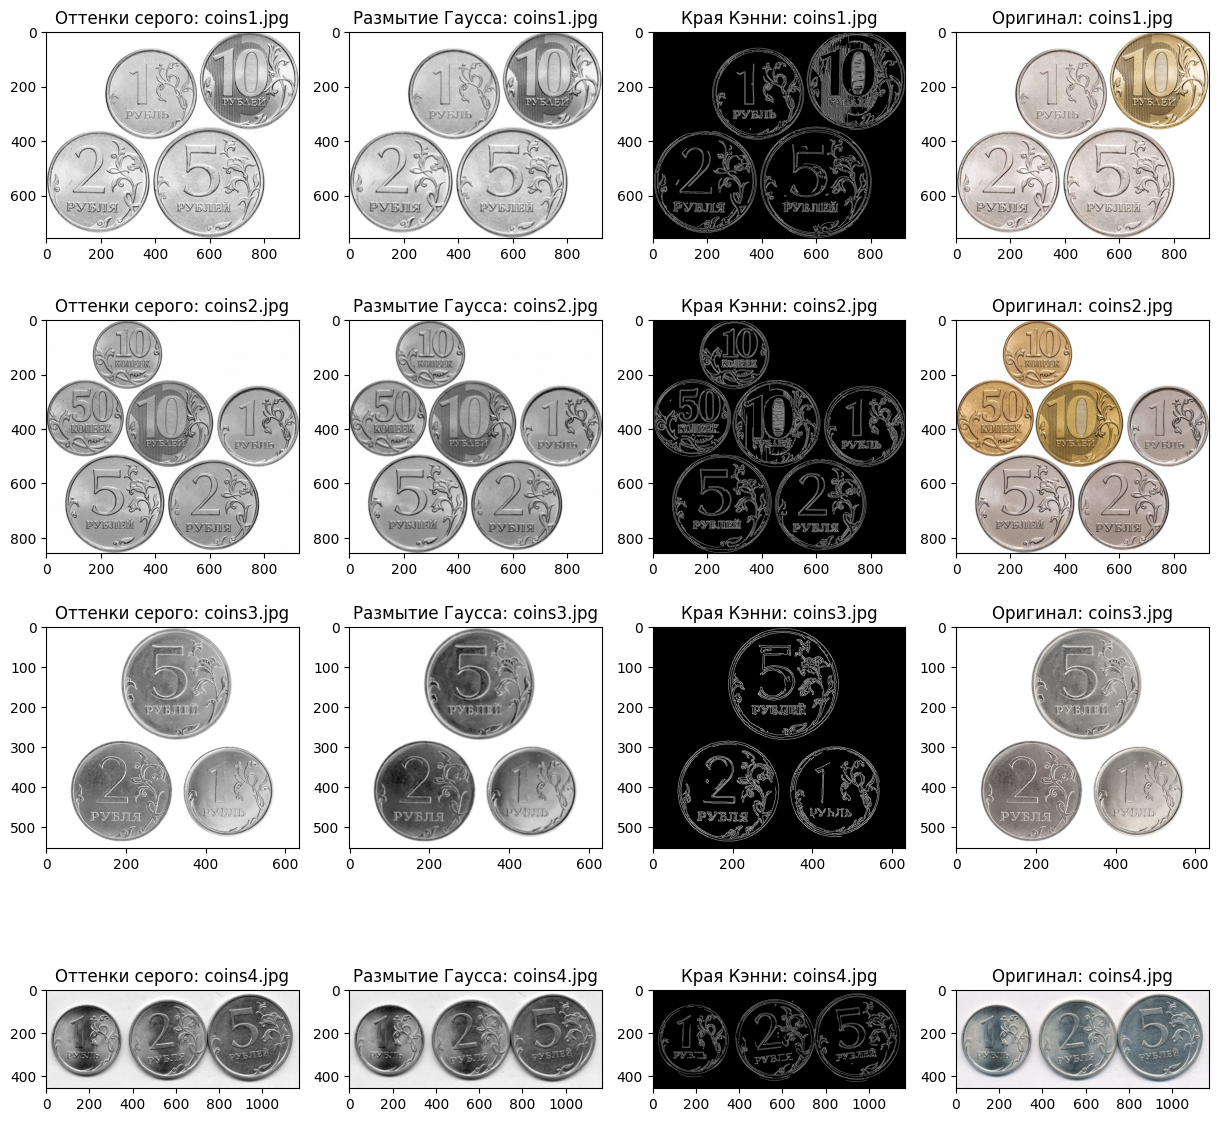

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загружаем 4 изображения и показываем этапы предобработки
image_names = ['coins1.jpg', 'coins2.jpg', 'coins3.jpg', 'coins4.jpg']

fig, axes = plt.subplots(nrows=len(image_names), ncols=4, figsize=(15, 15))
for i, image_name in enumerate(image_names):
    img = cv2.imread(image_name)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray_blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    c_anny = cv2.Canny(gray_blurred, 50, 150, apertureSize=3)

    axes[i, 0].imshow(gray, cmap='gray')
    axes[i, 0].set_title(f'Оттенки серого: {image_name}')
    axes[i, 1].imshow(gray_blurred, cmap='gray')
    axes[i, 1].set_title(f'Размытие Гаусса: {image_name}')
    axes[i, 2].imshow(c_anny, cmap='gray')
    axes[i, 2].set_title(f'Края Кэнни: {image_name}')
    axes[i, 3].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 3].set_title(f'Оригинал: {image_name}')
plt.show()


Монета 0: r=199, V=190, H=168, 5 руб.
Монета 1: r=186, V=217, H=162, 2 руб.
Монета 2: r=176, V=589, H=93, 10 руб.
Монета 3: r=164, V=169, H=98, 1 руб.
Найдено монет: 4
Номиналы монет: [5, 2, 10, 1]
Сумма: 18 рублей



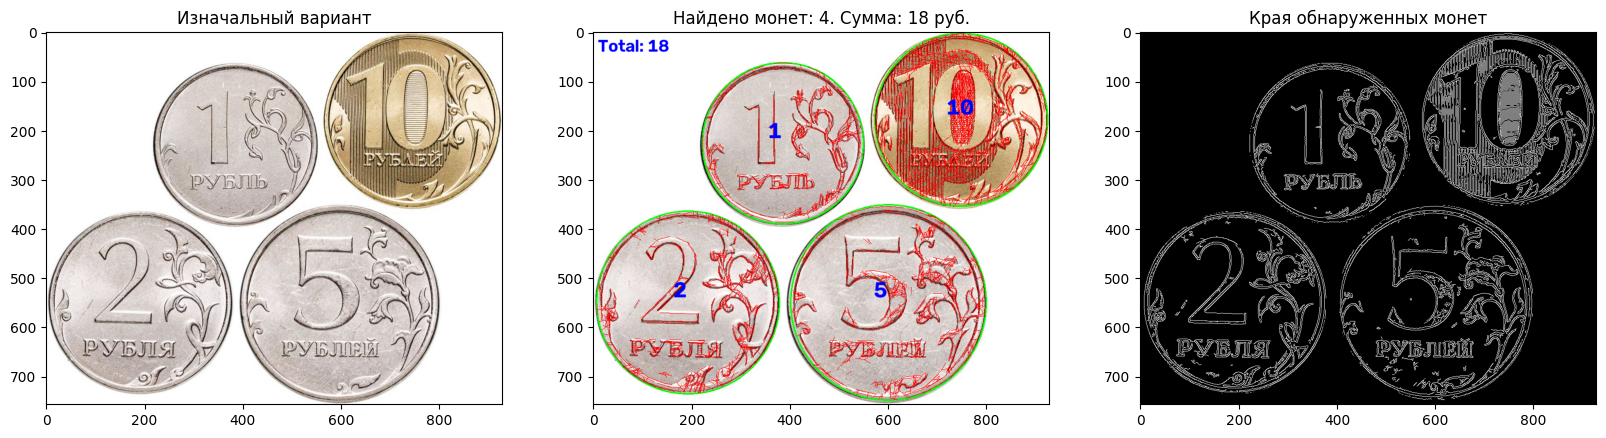

Монета 0: r=174, V=133, H=185, 5 руб.
Монета 1: r=148, V=171, H=119, 1 руб.
Монета 2: r=158, V=463, H=53, 10 руб.
Монета 3: r=140, V=109, H=126, 0.5 руб.
Монета 4: r=153, V=128, H=124, 2 руб.
Монета 5: r=117, V=54, H=100, 0.1 руб.
Найдено монет: 6
Номиналы монет: [5, 1, 10, 0.5, 2, 0.1]
Сумма: 18.6 рублей



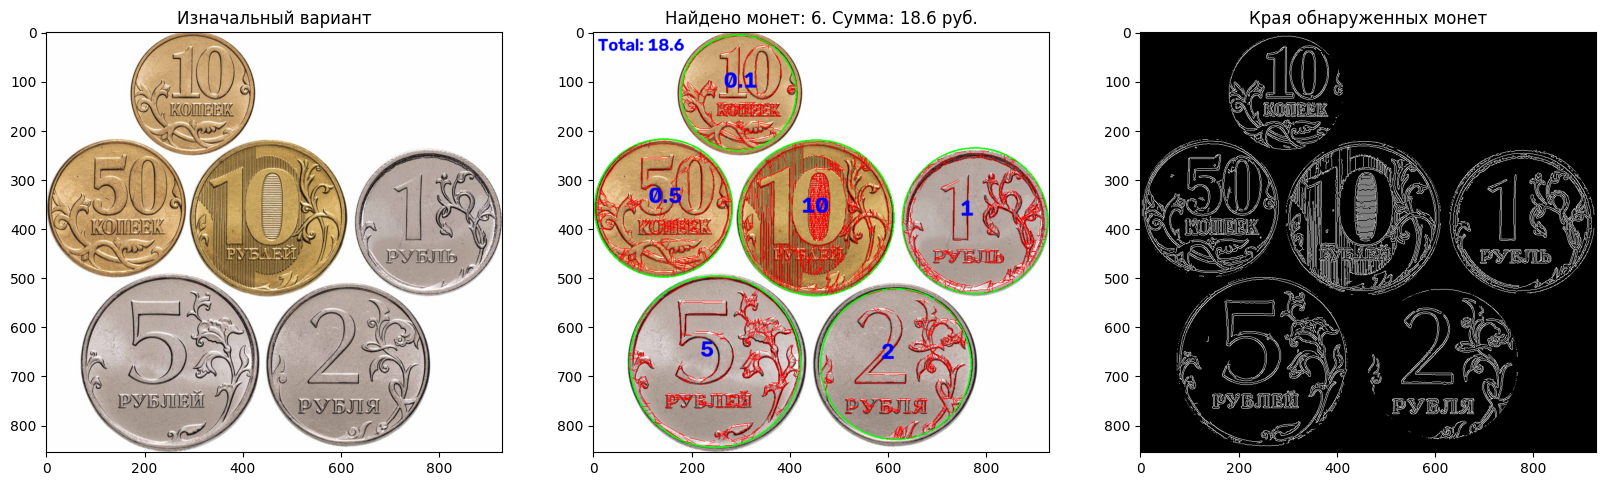

Монета 0: r=136, V=104, H=141, 5 руб.
Монета 1: r=107, V=88, H=39, 1 руб.
Монета 2: r=122, V=92, H=91, 2 руб.
Найдено монет: 3
Номиналы монет: [5, 1, 2]
Сумма: 8 рублей



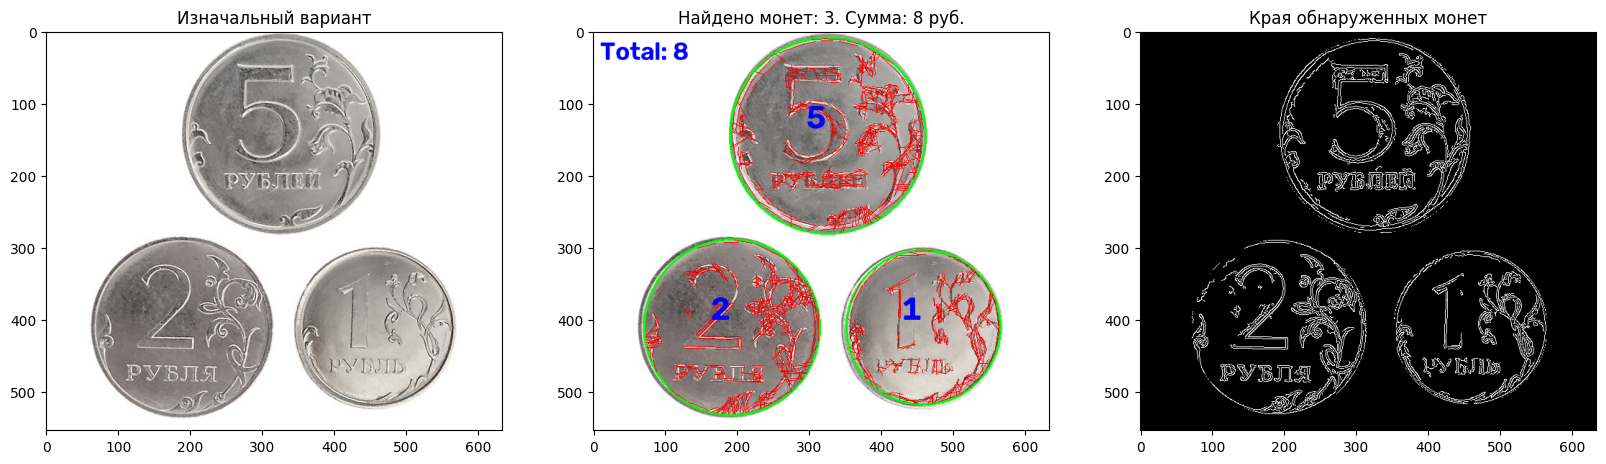

Монета 0: r=179, V=178, H=109, 2 руб.
Монета 1: r=195, V=120, H=138, 5 руб.
Монета 2: r=158, V=125, H=83, 1 руб.
Найдено монет: 3
Номиналы монет: [2, 5, 1]
Сумма: 8 рублей



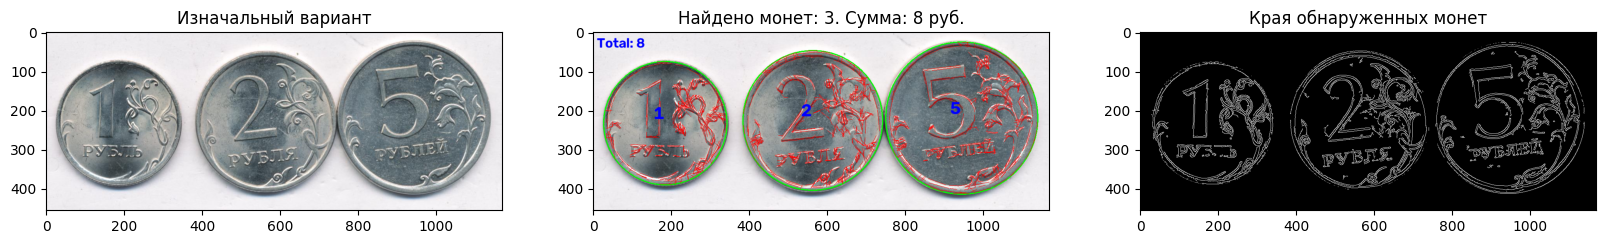

ИТОГО по всем изображениям: монет 16 , сумма 52.6 рублей


In [ ]:
#Параметры обнаружения для каждого файла
HOUGH_CFG = {
    'coins1.jpg': dict(preprocess='gauss', dp=1.2, minDist=200,
                       param1=50, param2=150, minRadius=150, maxRadius=250),
    'coins2.jpg': dict(preprocess='gauss', dp=1.2, minDist=200,
                       param1=50, param2=150, minRadius=100, maxRadius=250),
    'coins3.jpg': dict(preprocess='gauss', dp=1.2, minDist=200,
                       param1=50, param2=150, minRadius=100, maxRadius=250),
    'coins4.jpg': dict(preprocess='gauss', dp=1.2, minDist=200,
                       param1=50, param2=150, minRadius=100, maxRadius=250),
}

def find_coin_circles(image, params):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray_blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    circles = cv2.HoughCircles(
        gray_blurred, cv2.HOUGH_GRADIENT,
        params['dp'], params['minDist'],
        param1=params['param1'], param2=params['param2'],
        minRadius=params['minRadius'], maxRadius=params['maxRadius'],
    )
    return np.round(circles[0, :]).astype('int')

def coin_strokes(image, cx, cy, r, canny_low=50, canny_high=150,
                 hough_thresh=20, min_line_len=10, max_line_gap=5):
    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (cx, cy), r, 255, -1)
    x1 = max(cx - r, 0); y1 = max(cy - r, 0)
    x2 = min(cx + r, w); y2 = min(cy + r, h)
    roi = image[y1:y2, x1:x2]
    roi_mask = mask[y1:y2, x1:x2]
    roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY) if roi.ndim == 3 else roi
    roi_blur = cv2.GaussianBlur(roi_gray, (3, 3), 0)
    roi_edges = cv2.Canny(roi_blur, canny_low, canny_high)
    roi_edges = cv2.bitwise_and(roi_edges, roi_edges, mask=roi_mask)
    lines = cv2.HoughLinesP(
        roi_edges, rho=1, theta=np.pi / 180, threshold=hough_thresh,
        minLineLength=min_line_len, maxLineGap=max_line_gap,
    )
    result_lines = []
    if lines is not None:
        lines = np.asarray(lines).reshape(-1, 4)
        for lx1, ly1, lx2, ly2 in lines:
            result_lines.append([int(lx1) + x1, int(ly1) + y1,
                                 int(lx2) + x1, int(ly2) + y1])
    full_edges = np.zeros((h, w), dtype=np.uint8)
    full_edges[y1:y2, x1:x2] = roi_edges
    return result_lines, full_edges

def tally_strokes(lines):
    vertical_count = 0
    horizontal_count = 0
    for (x1, y1, x2, y2) in lines:
        dx, dy = x2 - x1, y2 - y1
        angle = np.degrees(np.arctan2(dy, dx)) % 180
        if angle < 20 or angle > 160:
            horizontal_count += 1
        elif 70 < angle < 110:
            vertical_count += 1
    return vertical_count, horizontal_count

def _vote(value, refs, tol):
    in_range = [(nom, abs(value - ref)) for nom, ref in refs if abs(value - ref) <= tol]
    if in_range:
        return min(in_range, key=lambda x: (x[1], x[0]))[0]
    return min(refs, key=lambda kv: abs(value - kv[1]))[0]

NOMINAL_TABLE = {
    'coins1.jpg': [(1, 164, 169, 98), (2, 186, 217, 162),
                   (5, 199, 190, 168), (10, 176, 589, 93)],
    'coins2.jpg': [(0.1, 117, 54, 100), (0.5, 140, 109, 126),
                   (1, 148, 171, 119), (10, 158, 463, 53),
                   (5, 174, 133, 185), (2, 153, 128, 124)],
    'coins3.jpg': [(1, 107, 88, 39), (2, 122, 92, 91), (5, 136, 104, 141)],
    'coins4.jpg': [(1, 158, 125, 83), (2, 179, 178, 109), (5, 195, 120, 138)],
}
DEVIATION = {'radius': 8, 'vertical': 40, 'horizontal': 40}

def resolve_nominal(fname, radius, vertical_count, horizontal_count):
    table = NOMINAL_TABLE[fname]
    votes_by_criterion = {
        'radius':     _vote(radius,
                            [(n, r) for n, r, v, h in table],
                            DEVIATION['radius']),
        'vertical':   _vote(vertical_count,
                            [(n, v) for n, r, v, h in table],
                            DEVIATION['vertical']),
        'horizontal': _vote(horizontal_count,
                            [(n, h) for n, r, v, h in table],
                            DEVIATION['horizontal']),
    }
    vote_counts = {nom: 0 for nom, *_ in table}
    for nom in votes_by_criterion.values():
        vote_counts[nom] += 1
    if max(vote_counts.values()) == 1:
        return votes_by_criterion['radius'], votes_by_criterion
    max_count = max(vote_counts.values())
    tied = [nom for nom, cnt in vote_counts.items() if cnt == max_count]
    if len(tied) == 1:
        winner = tied[0]
    else:
        winner = (votes_by_criterion['radius']
                  if votes_by_criterion['radius'] in tied else min(tied))
    return winner, votes_by_criterion

#основной цикл по 4 файлам
grand_total = 0
grand_count = 0
summary_rows = []

for image_name in image_names:
    img = cv2.imread(image_name)
    params = HOUGH_CFG[image_name]
    circles = find_coin_circles(img, params)
    result = img.copy()
    all_edges = np.zeros(img.shape[:2], dtype=np.uint8)
    coin_values = []
    coin_info = []

    for i, (cx, cy, r) in enumerate(circles):
        lines, edges = coin_strokes(img, cx, cy, r)
        vertical_count, horizontal_count = tally_strokes(lines)
        nominal, votes = resolve_nominal(image_name, r, vertical_count, horizontal_count)
        coin_values.append(nominal)
        coin_info.append((i, cx, cy, r, vertical_count, horizontal_count, nominal))
        # зелёная окружность вокруг монеты
        cv2.circle(result, (cx, cy), r, (0, 255, 0), 2)
        # красные границы штрихов внутри монеты
        for (x1, y1, x2, y2) in lines:
            cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 1)
        all_edges = cv2.bitwise_or(all_edges, edges)
        print(f'Монета {i}: r={r}, V={vertical_count}, H={horizontal_count}, {nominal} руб.')

    total = sum(coin_values)
    for (i, cx, cy, r, v, h, nominal) in coin_info:
        cv2.putText(result, str(nominal), (cx - 30, cy - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 0, 0), 3)
    cv2.putText(result, 'Total: ' + str(total), (10, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 0, 0), 3)
    print('Найдено монет:', len(coin_values))
    print('Номиналы монет:', coin_values)
    print('Сумма:', total, 'рублей')
    print()

    grand_total += total
    grand_count += len(coin_values)
    summary_rows.append((image_name, len(coin_values), coin_values, total))

    plt.figure(figsize=(20, 10))
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('Изначальный вариант')
    plt.subplot(1, 3, 2)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f'Найдено монет: {len(coin_values)}. Сумма: {total} руб.')
    plt.subplot(1, 3, 3)
    plt.imshow(all_edges, cmap='gray')
    plt.title('Края обнаруженных монет')
    plt.show()

print('ИТОГО по всем изображениям: монет', grand_count, ', сумма', grand_total, 'рублей')


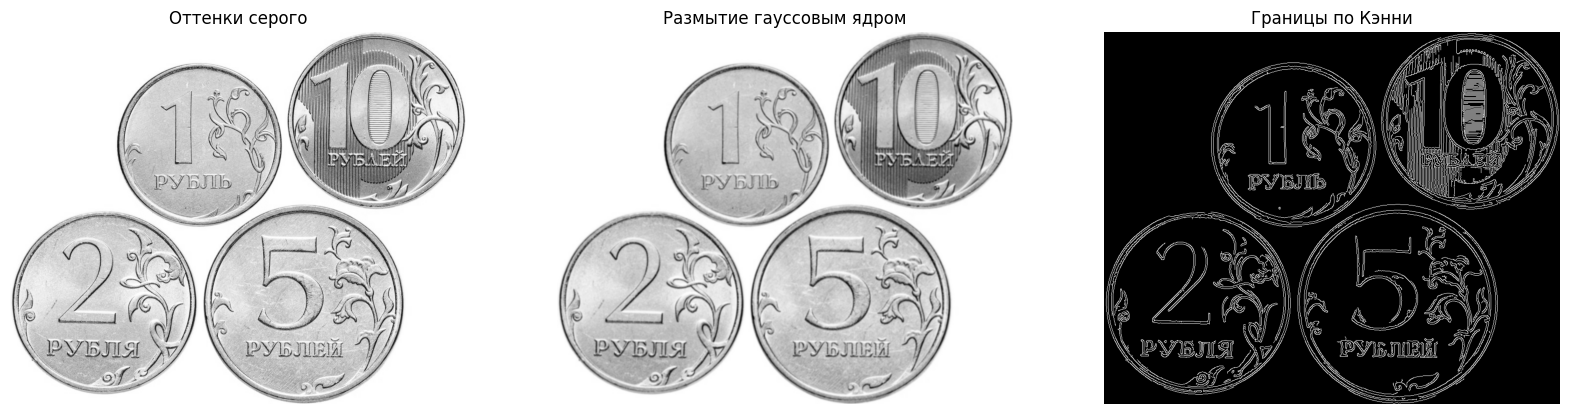

In [ ]:
# Детальный разбор coins1: предобработка по шагам
sample_file = 'coins1.jpg'
sample_frame = cv2.imread(sample_file)

step_mono = cv2.cvtColor(sample_frame, cv2.COLOR_BGR2GRAY)
# гауссово ядро 5x5 из теории
kernel_gauss = (1 / 256) * np.array([
    [1, 4, 6, 4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1, 4, 6, 4, 1],
], dtype=np.float32)
step_smooth = cv2.filter2D(step_mono, -1, kernel_gauss)
step_edges = cv2.Canny(step_smooth, 50, 200)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
axes[0].imshow(step_mono, cmap='gray')
axes[0].set_title('Оттенки серого')
axes[1].imshow(step_smooth, cmap='gray')
axes[1].set_title('Размытие гауссовым ядром')
axes[2].imshow(step_edges, cmap='gray')
axes[2].set_title('Границы по Кэнни')
for ax in axes:
    ax.axis('off')
plt.show()


радиус=199px, вертикальных=190, горизонтальных=168, голоса={'radius': 5, 'vertical': 5, 'horizontal': 5} -> номинал 5 руб.
радиус=186px, вертикальных=217, горизонтальных=162, голоса={'radius': 2, 'vertical': 2, 'horizontal': 2} -> номинал 2 руб.
радиус=176px, вертикальных=589, горизонтальных=93, голоса={'radius': 10, 'vertical': 10, 'horizontal': 10} -> номинал 10 руб.
радиус=164px, вертикальных=169, горизонтальных=98, голоса={'radius': 1, 'vertical': 1, 'horizontal': 1} -> номинал 1 руб.

Проверка: найдено 4 монет, сумма 18 руб. (ожидаем 4 монеты и 18 руб.)


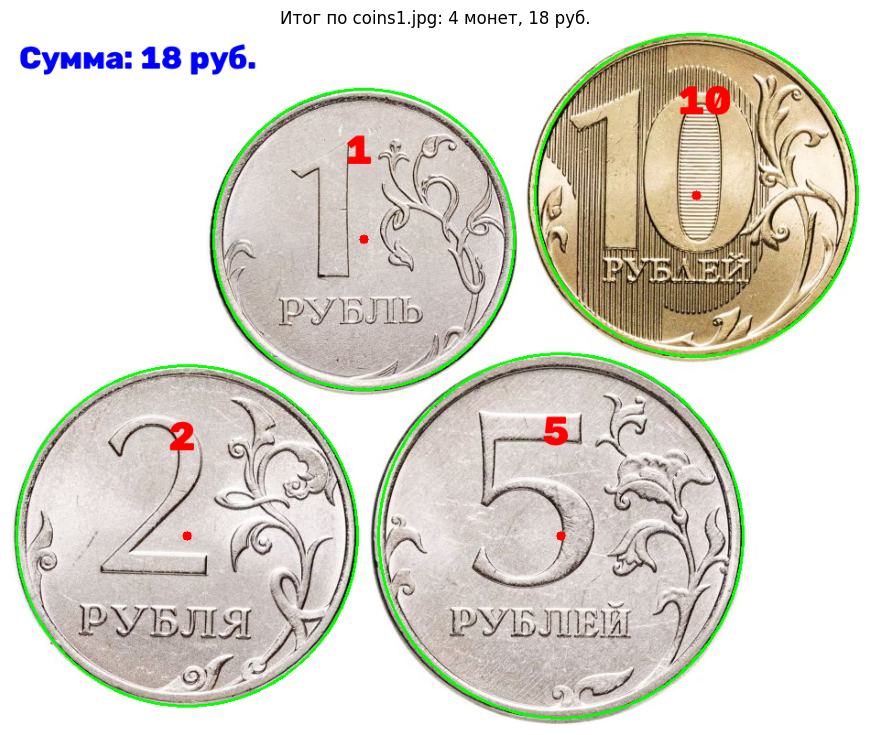

In [ ]:
# Основной алгоритм по coins1 с подробным выводом
sample_file = 'coins1.jpg'
sample_frame = cv2.imread(sample_file)
sample_circles = find_coin_circles(sample_frame, HOUGH_CFG[sample_file])
sample_result = sample_frame.copy()
sample_records = []

for cx, cy, r in sample_circles:
    strokes, _ = coin_strokes(sample_frame, cx, cy, r)
    v_cnt, h_cnt = tally_strokes(strokes)
    nominal, votes = resolve_nominal(sample_file, r, v_cnt, h_cnt)
    sample_records.append((cx, cy, r, v_cnt, h_cnt, nominal, votes))
    print(f'радиус={r}px, вертикальных={v_cnt}, горизонтальных={h_cnt}, голоса={votes} -> номинал {nominal} руб.')

sample_total = sum(rec[5] for rec in sample_records)

for cx, cy, r, v_cnt, h_cnt, nominal, _ in sample_records:
    # зелёный контур монеты
    cv2.circle(sample_result, (cx, cy), r, (0, 255, 0), 2)
    # красный центр
    cv2.circle(sample_result, (cx, cy), 5, (0, 0, 255), -1)
    # красный номинал
    cv2.putText(sample_result, str(nominal), (cx - 20, cy - r // 2),
                cv2.FONT_HERSHEY_COMPLEX, 1.5, (0, 0, 255), 3)

cv2.putText(sample_result, 'Сумма: ' + str(sample_total) + ' руб.',
            (10, 40), cv2.FONT_HERSHEY_COMPLEX, 1.2, (255, 0, 0), 3)

print()
print(f'Проверка: найдено {len(sample_records)} монет, сумма {sample_total} руб. (ожидаем 4 монеты и 18 руб.)')

plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(sample_result, cv2.COLOR_BGR2RGB))
plt.title(f'Итог по {sample_file}: {len(sample_records)} монет, {sample_total} руб.')
plt.axis('off')
plt.show()


Найдено отрезков (HoughLinesP): 3416


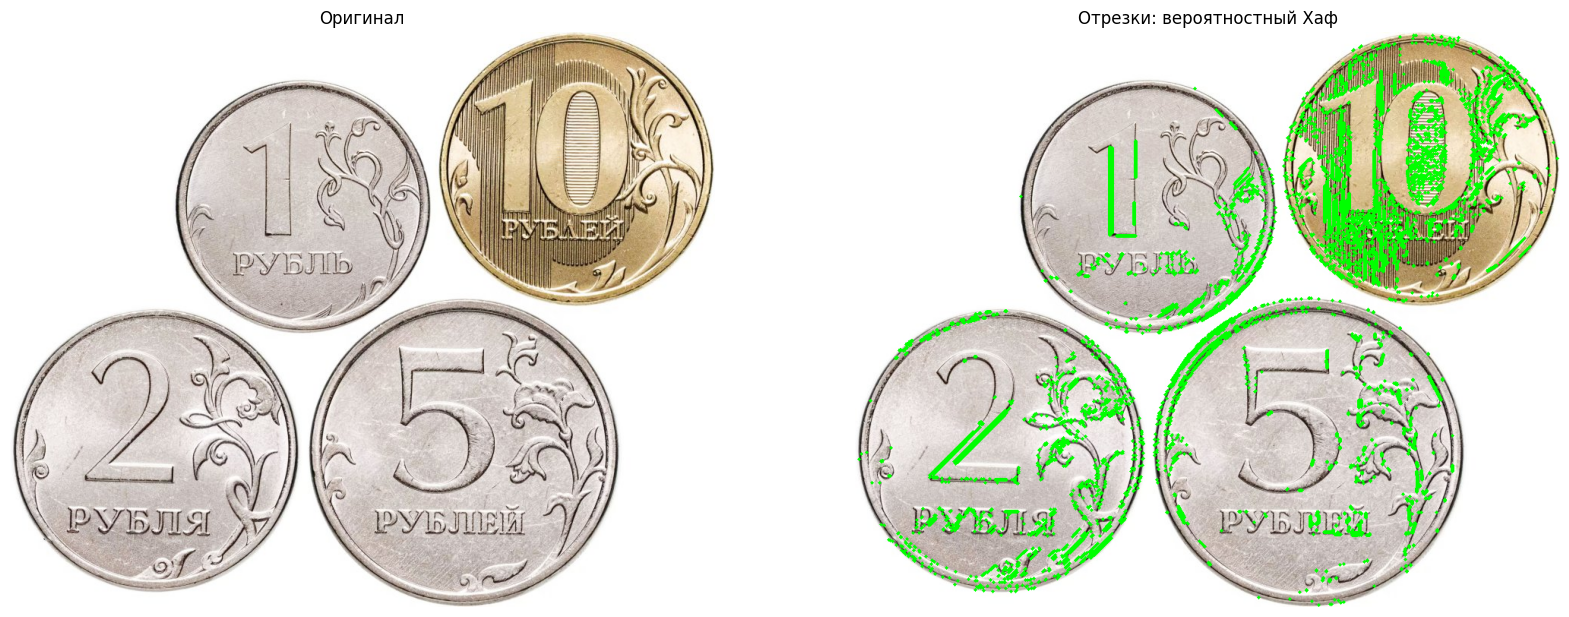

In [ ]:
# HoughLinesP: отрезки по всему кадру
step_rho = 1
step_theta = np.pi / 180
step_votes = 130

found_segments = cv2.HoughLinesP(step_edges, step_rho, step_theta, step_votes,
                                 minLineLength=0, maxLineGap=None)
show_segments = sample_frame.copy()

if found_segments is not None:
    for x1, y1, x2, y2 in np.asarray(found_segments).reshape(-1, 4):
        cv2.line(show_segments, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 3)
    print('Найдено отрезков (HoughLinesP):', len(found_segments))
else:
    print('Отрезки не найдены')

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
axes[0].imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал')
axes[1].imshow(cv2.cvtColor(show_segments, cv2.COLOR_BGR2RGB))
axes[1].set_title('Отрезки: вероятностный Хаф')
for ax in axes:
    ax.axis('off')
plt.show()


In [ ]:
# Сводная таблица по всем изображениям
print('%-12s %6s  %-30s %10s' % ('файл', 'монет', 'номиналы', 'сумма'))
print('-' * 66)
for fname, count, nominals, subtotal in summary_rows:
    print('%-12s %6d  %-30s %10s' % (fname, count, str(nominals), '%g' % subtotal))
print('-' * 66)
print('%-12s %6d  %-30s %10s' % ('ВСЕГО', grand_count, '', '%g' % grand_total))


файл          монет  номиналы                            сумма
------------------------------------------------------------------
coins1.jpg        4  [5, 2, 10, 1]                          18
coins2.jpg        6  [5, 1, 10, 0.5, 2, 0.1]              18.6
coins3.jpg        3  [5, 1, 2]                               8
coins4.jpg        3  [2, 5, 1]                               8
------------------------------------------------------------------
ВСЕГО            16                                       52.6


## Выводы

1. `cv2.HoughCircles` надёжно обнаруживает круглые объекты (монеты) на изображении.
2. `cv2.HoughLinesP` внутри каждой монеты позволяет извлечь штрихи текста — вертикальные и горизонтальные.
3. Голосование по трём критериям (радиус, V, H) позволяет отличить номиналы, которые имеют близкий радиус.
4. `cv2.HoughLines` даёт бесконечные прямые по всему кадру, а `HoughLinesP` — отрезки, что удобнее для анализа конкретных объектов.
5. Программа обрабатывает 4 изображения, находит 16 монет и вычисляет общую сумму 52.6 руб.
